Best Feature: Glucose
Worst Feature: BloodPressure


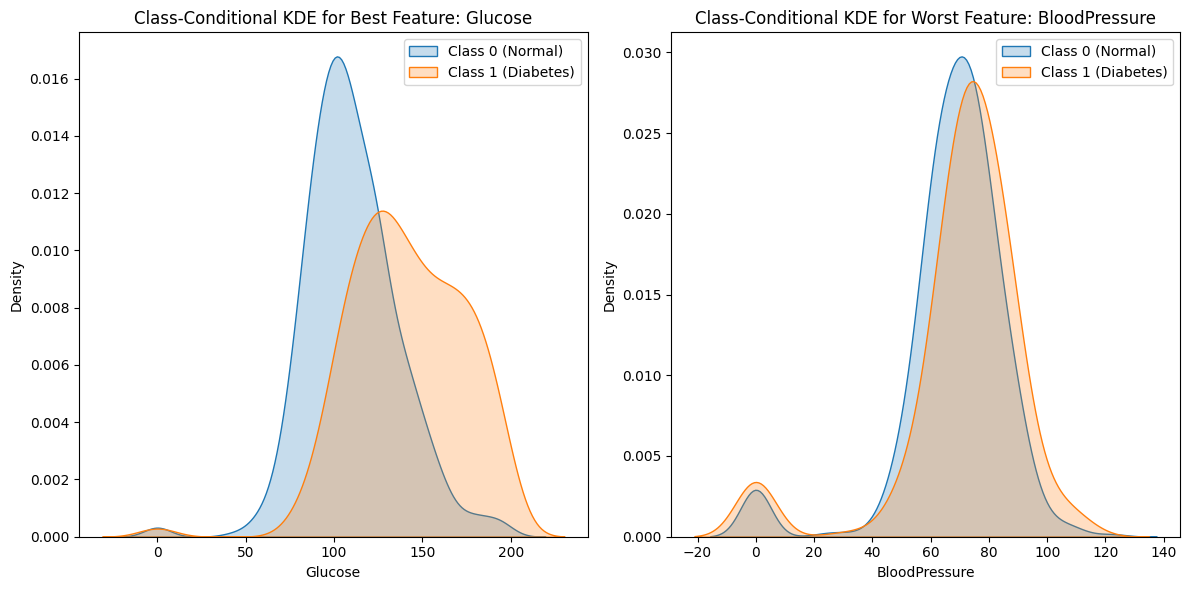

In [4]:
# Required libraries
import numpy as np
import pandas as pd
from scipy.io import arff
from sklearn.feature_selection import f_classif
import matplotlib.pyplot as plt
import seaborn as sns

# Load the ARFF data
data, meta = arff.loadarff('diabetes.arff')

# Convert to pandas DataFrame
df = pd.DataFrame(data)

# Ensure the 'Outcome' column is treated as categorical (0, 1)
df['Outcome'] = df['Outcome'].astype(int)

# Separate features and target
X = df.drop('Outcome', axis=1)  # features
y = df['Outcome']               # target

# Apply ANOVA F-test
f_values, p_values = f_classif(X, y)

# Create a DataFrame to show the results
anova_results = pd.DataFrame({
    'Feature': X.columns,
    'F-Value': f_values,
    'P-Value': p_values
}).sort_values(by='F-Value', ascending=False)

# Display the features with the best and worst discriminative power
best_feature = anova_results.iloc[0]['Feature']
worst_feature = anova_results.iloc[-1]['Feature']

print(f"Best Feature: {best_feature}")
print(f"Worst Feature: {worst_feature}")

# Plot class-conditional probability density functions for best and worst features
plt.figure(figsize=(12, 6))

# Best Feature KDE plot
plt.subplot(1, 2, 1)
sns.kdeplot(df[best_feature][df['Outcome'] == 0], label='Class 0 (Normal)', fill=True)
sns.kdeplot(df[best_feature][df['Outcome'] == 1], label='Class 1 (Diabetes)', fill=True)
plt.title(f'Class-Conditional KDE for Best Feature: {best_feature}')
plt.xlabel(best_feature)
plt.legend()

# Worst Feature KDE plot
plt.subplot(1, 2, 2)
sns.kdeplot(df[worst_feature][df['Outcome'] == 0], label='Class 0 (Normal)', fill=True)
sns.kdeplot(df[worst_feature][df['Outcome'] == 1], label='Class 1 (Diabetes)', fill=True)
plt.title(f'Class-Conditional KDE for Worst Feature: {worst_feature}')
plt.xlabel(worst_feature)
plt.legend()

plt.tight_layout()
plt.show()

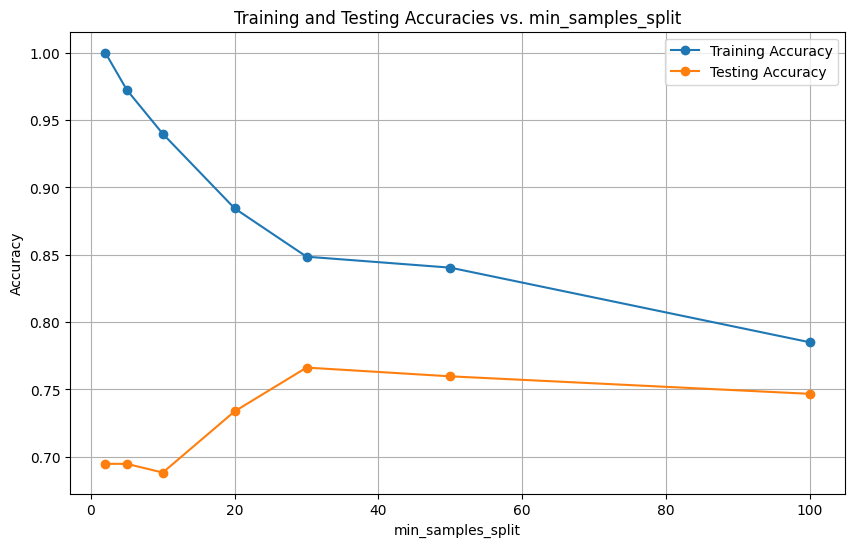

In [5]:
# Required libraries
import numpy as np
import pandas as pd
from scipy.io import arff
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Load the ARFF data
data, meta = arff.loadarff('diabetes.arff')

# Convert to pandas DataFrame
df = pd.DataFrame(data)

# Ensure the 'Outcome' column is treated as categorical (0, 1)
df['Outcome'] = df['Outcome'].astype(int)

# Separate features and target
X = df.drop('Outcome', axis=1)  # features
y = df['Outcome']               # target

# Perform a stratified 80-20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=1)

# Values for min_samples_split
min_samples_splits = [2, 5, 10, 20, 30, 50, 100]

# Lists to store accuracies
train_accuracies = []
test_accuracies = []

# Loop through the different min_samples_split values
for min_samples in min_samples_splits:
    # Initialize Decision Tree Classifier with given min_samples_split
    clf = DecisionTreeClassifier(min_samples_split=min_samples, random_state=1)
    
    # Train the model on training data
    clf.fit(X_train, y_train)
    
    # Predict on training and testing sets
    y_train_pred = clf.predict(X_train)
    y_test_pred = clf.predict(X_test)
    
    # Calculate accuracy for both training and testing sets
    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)
    
    # Append accuracies to the respective lists
    train_accuracies.append(train_accuracy)
    test_accuracies.append(test_accuracy)

# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(min_samples_splits, train_accuracies, label='Training Accuracy', marker='o')
plt.plot(min_samples_splits, test_accuracies, label='Testing Accuracy', marker='o')

# Add labels and title
plt.xlabel('min_samples_split')
plt.ylabel('Accuracy')
plt.title('Training and Testing Accuracies vs. min_samples_split')
plt.legend()

# Show the plot
plt.grid(True)
plt.show()
